# Run 5: a Galaxy with bright patches (towards a needlet sky model)

Goal of run 5: simulate a Galaxy that is **not** a single Gaussian, with a few compact patches of excess power, and later
ask whether a needlet description of the sky can recover them from 30 days of A/E data. This first section only
builds and shows the simulated sky and the power modulation $P_c(t)$ it produces. No time series is simulated yet.

**How the sky is built** ([sky_patches.py](sky_patches.py), [config/run5_sky.yaml](config/run5_sky.yaml)):

* **One spectrum, many places.** All Galactic power comes from unresolved DWDs with the common spectrum
  $S_{\rm gal}(f)$ of run 2. The components differ only in where on the sky the power sits. The sky is a HEALPix map
  $I(\hat n)$ of flux per pixel (nside 64), and the modulation is linear in it:

```math
P_c(t) = k\,\frac{1}{\bar R}\sum_{\rm pix} I({\rm pix})\, R_c(t,{\rm pix}), \qquad R_c = F_{+,c}^2 + F_{\times,c}^2 ,
```

  with the first-principles low-frequency A/E response $R_c$ of [../needlet_patches/sky.py](../needlet_patches/sky.py)
  (bahamas orbit; evaluated on the map degraded to nside 32, which is exact since $R_c$ has only ℓ = 0, 2, 4).
* **Smooth Galaxy = run 2's Galaxy.** The bivariate Gaussian in ecliptic (β, λ) behind `envelopes_gaussian`, with the
  pack-2 sky parameters of [config/sources.yaml](config/sources.yaml) (centred on the Galactic centre, σ ≈ 12° × 21°),
  written out pixel by pixel. The formula integrates the density with the measure cos β dβ dλ, so the flux per pixel is
  $p(\beta,\lambda)\,\Delta\Omega$. One constant $k$ is fitted so that this map reproduces run 2's analytic $M_c^2(t)$.
  It does so to 0.1% (A) and 0.2% (E) over the 30 days. **Run 5's smooth part is therefore run 2's injection, at the
  same `amp`**, and the patches come on top.
* **Patches**: elliptical Gaussians on the sphere at the positions of real structures that host old stars (hence DWDs),
  with sizes of the order of their stellar bodies:

  | patch | (l, b) | σ major × minor | why |
  |---|---|---|---|
  | LMC | (280.5°, −32.9°) | 3.0° × 2.2° | largest satellite; its DWD population has been studied as a LISA source |
  | SMC | (302.8°, −44.3°) | 1.6° × 1.0° | 20° from the LMC: two nearby patches that blend at low ℓ |
  | Sgr dSph | (5.6°, −14.2°) | 4.0° × 1.5° (along b) | core elongated perpendicular to the plane, 14° below the centre, i.e. **on top of** the smooth Galaxy |
  | bar end | (27°, 0°) | 6.0° × 1.5° (along l) | near end of the Galactic long bar: an in-plane overdensity the Gaussian Galaxy lacks |

* **Fluxes are exaggerated on purpose** (LMC 20%, SMC 8%, Sgr 12%, bar end 12% of the smooth Galaxy's flux, 52% in
  total). With the same DWD rate per stellar mass, the realistic flux fraction $M/d^2$ relative to the Milky Way is
  about $6\times10^{-4}$ (LMC), $8\times10^{-5}$ (Sgr) and $5\times10^{-5}$ (SMC) (printed below), far below anything
  30 days can see. The amplitudes are a single knob per patch in the config.


In [1]:
import sys
from pathlib import Path
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
HERE = ROOT / 'data' / 'wavelet_injection'
sys.path.insert(0, str(HERE))
import sky_patches as SP
from bahamas.wavelet.model import DAY

OUT = HERE / 'outputs' / 'run5'
OUT.mkdir(parents=True, exist_ok=True)
CH = ['A', 'E']
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
C_GAL = '#2a78d6'
C_PATCH = ['#eb6834', '#1baf7a', '#eda100', '#e87ba4']      # categorical, fixed order = config order
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.titlesize': 9, 'axes.labelsize': 9,
                     'legend.fontsize': 8, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'lines.linewidth': 1.6})

sky = SP.Run5Sky()
patches = sky.cfg['patches']
print(f"smooth Galaxy (map) vs run 2's analytic M_c^2(t), max rel. difference: A {sky.galaxy_match()[0]:.1e}, "
      f"E {sky.galaxy_match()[1]:.1e}  (k = {sky.k:.3f})")
real = SP.realistic_flux()
for p in patches:
    r = real.get(p['name'])
    print(f"{p['name']:9s} flux {p['flux']:.2f} of the Galaxy   realistic M/d^2: " + (f"{r:.1e}  (boost x{p['flux'] / r:.0f})" if r else '-'))

2026-10-17 10:31:39,495 - BAHAMAS - INFO - Using JAX backend.


2026-10-17 10:31:39,496 - BAHAMAS - INFO - np is from: jax.numpy


smooth Galaxy (map) vs run 2's analytic M_c^2(t), max rel. difference: A 9.5e-04, E 1.8e-03  (k = 5.539)
LMC       flux 0.20 of the Galaxy   realistic M/d^2: 6.4e-04  (boost x313)
SMC       flux 0.08 of the Galaxy   realistic M/d^2: 4.7e-05  (boost x1703)
Sgr dSph  flux 0.12 of the Galaxy   realistic M/d^2: 8.3e-05  (boost x1447)
bar end   flux 0.12 of the Galaxy   realistic M/d^2: -


## 1. The simulated sky

Top: the full sky in galactic coordinates (log scale, so the broad Gaussian and the compact patches are both visible).
Bottom left: the patches alone. Bottom right: the part of the patches an A/E auto-power analysis can see at all,
the even harmonics ℓ = 0, 2, 4 of the map (the response contains nothing else, so the rest of the map has no
effect on $P_c(t)$). That is the ceiling for any sky model, needlets included.

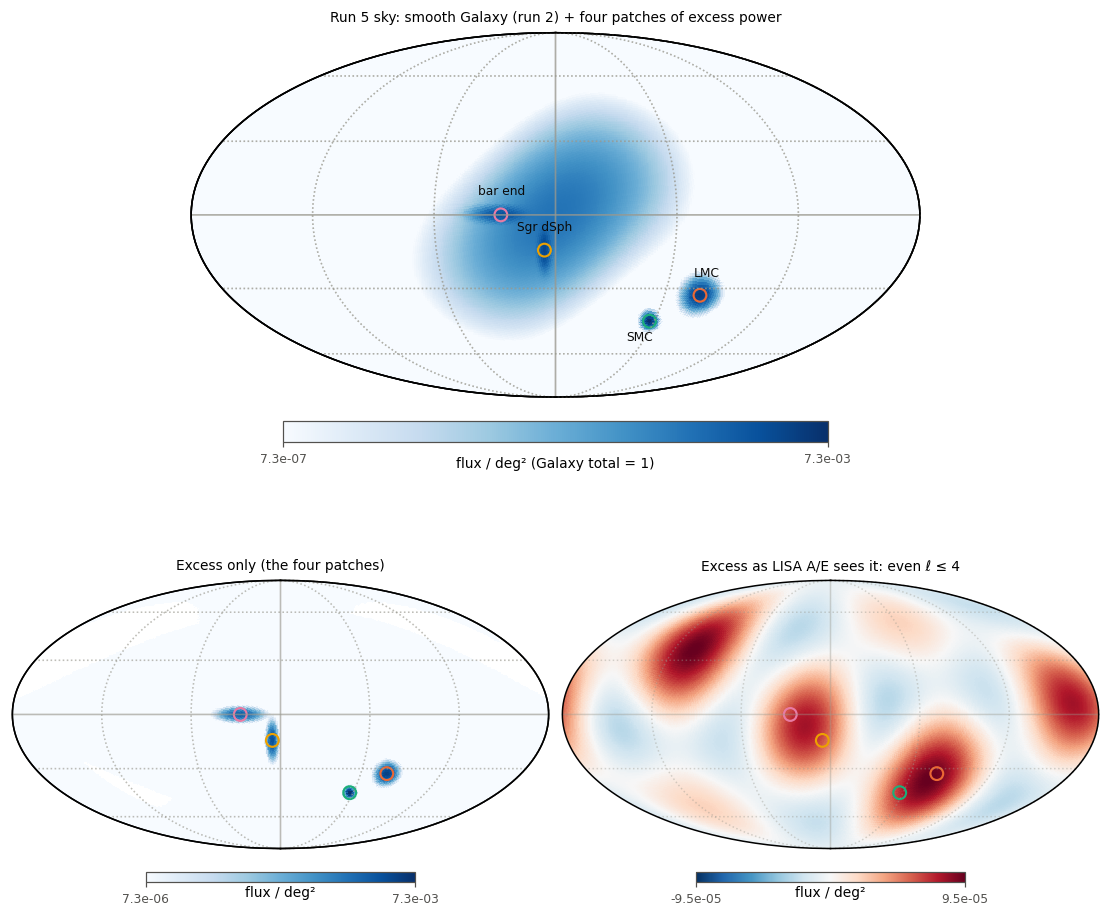

share of the excess map's power (sum of squares) in even l <= 4: 0.035
Galaxy flux within 10 deg of its centre: 0.18


In [2]:
def show(m, sub, title, unit, **kw):
    hp.mollview(m, coord=['E', 'G'], sub=sub, title=title, unit=unit, cbar=True, notext=True, bgcolor='white',
                badcolor='white', format='%.1e', fontsize={'title': 10, 'cbar_label': 9, 'cbar_tick_label': 8}, **kw)
    hp.graticule(dpar=30, dmer=60, color='#9a998f', alpha=0.4)

def mark_patches(labels=True):
    for p, c in zip(patches, C_PATCH):
        hp.projscatter(p['l'], p['b'], lonlat=True, coord='G', s=70, facecolors='none', edgecolors=c, linewidths=1.4)
        if labels:
            dy = -9 if p['name'] == 'SMC' else 8
            hp.projtext(p['l'], p['b'] + dy, p['name'], lonlat=True, coord='G', fontsize=8, color=INK, ha='center')

pix_area_deg2 = hp.nside2pixarea(sky.cfg['maps']['nside'], degrees=True)
total = sky.total_map / pix_area_deg2           # flux per deg^2 (Galaxy total flux = 1)
excess = sky.excess_map / pix_area_deg2
vis = SP.skyresp.bandlimit(sky.excess_map, lmax=4) / pix_area_deg2

fig = plt.figure(figsize=(10, 8.2))
show(total, (2, 1, 1), 'Run 5 sky: smooth Galaxy (run 2) + four patches of excess power', 'flux / deg² (Galaxy total = 1)',
     norm='log', min=total.max() * 1e-4, max=total.max(), cmap='Blues')
mark_patches()
show(excess, (2, 2, 3), 'Excess only (the four patches)', 'flux / deg²', norm='log', min=excess.max() * 1e-3,
     max=excess.max(), cmap='Blues')
mark_patches(labels=False)
vmax = np.abs(vis).max()
show(vis, (2, 2, 4), 'Excess as LISA A/E sees it: even ℓ ≤ 4', 'flux / deg²', min=-vmax, max=vmax, cmap='RdBu_r')
mark_patches(labels=False)
fig.savefig(OUT / 'sky.png', bbox_inches='tight')
plt.show()

frac_vis = np.sum(vis ** 2) / np.sum(excess ** 2)
print(f"share of the excess map's power (sum of squares) in even l <= 4: {frac_vis:.3f}")
print(f"Galaxy flux within 10 deg of its centre: "
      f"{sky.maps['galaxy'][np.degrees(np.arccos(SP.skyresp.pixel_vectors(64).T @ SP.skyresp.galactic_direction(0, 0))) < 10].sum():.2f}")

## 2. The power modulation $P_c(t)$ over the 30 days

Top: total $P_c(t)$ (smooth + patches) against the smooth Galaxy alone (= run 2's injection). Bottom: each patch's
contribution relative to the smooth Galaxy. The same flux gives a different excess in A and in E and changes with
time, because each patch sits at a different place in the antenna pattern. That time and channel dependence is the
only handle the data have on where a patch is.

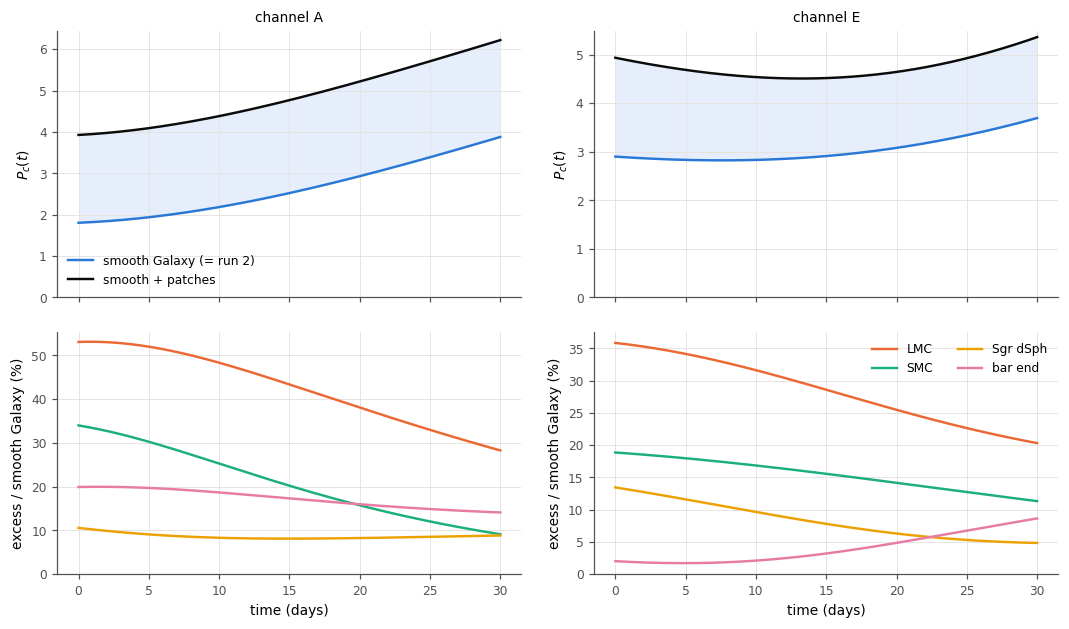

30-day mean galactic power relative to the smooth Galaxy:
  A: LMC +41%, SMC +19%, Sgr dSph +9%, bar end +17%, all patches +85%
  E: LMC +28%, SMC +15%, Sgr dSph +8%, bar end +4%, all patches +56%


In [3]:
w = (sky.times >= sky.t0) & (sky.times <= sky.t0 + sky.T)
td = sky.times[w] / DAY
Pc = sky.P_components[:, w]                      # (2, nt, 1 + npatch)
plt.rcParams.update({'xtick.labelsize': 8, 'ytick.labelsize': 8})   # healpy resets them
fig, ax = plt.subplots(2, 2, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [1.1, 1]})
for c in range(2):
    a = ax[0, c]
    a.plot(td, Pc[c, :, 0], color=C_GAL, label='smooth Galaxy (= run 2)')
    a.plot(td, Pc[c].sum(-1), color=INK, label='smooth + patches')
    a.fill_between(td, Pc[c, :, 0], Pc[c].sum(-1), color=C_GAL, alpha=0.12, lw=0)
    a.set_title(f'channel {CH[c]}'); a.set_ylabel(r'$P_c(t)$')
    a.set_ylim(0, None)
    a = ax[1, c]
    for i, (p, col) in enumerate(zip(patches, C_PATCH)):
        a.plot(td, 100 * Pc[c, :, 1 + i] / Pc[c, :, 0], color=col, label=p['name'])
    a.set_ylabel('excess / smooth Galaxy (%)'); a.set_xlabel('time (days)'); a.set_ylim(0, None)
ax[0, 0].legend(frameon=False, loc='lower left')
ax[1, 1].legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(OUT / 'modulation.png', bbox_inches='tight')
plt.show()

print('30-day mean galactic power relative to the smooth Galaxy:')
for c in range(2):
    m = Pc[c].mean(0) / Pc[c, :, 0].mean()
    print(f"  {CH[c]}: " + ', '.join(f"{p['name']} +{100 * m[1 + i]:.0f}%" for i, p in enumerate(patches))
          + f", all patches +{100 * (m[1:].sum()):.0f}%")